In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit
from tqdm import tqdm

plt.rcParams['figure.figsize'] = [8.0, 8.0]
plt.rcParams['figure.dpi'] = 140



_EPS_ = 1e-6

In [2]:
#@njit
def run_abp_core(x, y, phi, dt, tau_func,
                 Pe=1, Dt=0, Dr=1, eps=100):
    '''
    Simulate an ABP with Euler-Maruyama steps of step width dt.
    The first entries of x, y, and phi form the initial condition,
    the rest of the entries get filled by this function, altering
    existing data.
    '''

    n_steps = x.shape[0]

    for i in range(0, n_steps-1):

        x_ = x[i]
        y_ = y[i]
        phi_ = phi[i]

        F = 0
        if x_ > -2**(-1/6):
            F = 24*eps*((1/(x_+_EPS_))**13 - 2*(1/(x_+_EPS_))**7)

        torque = tau_func(phi_) * F - 0.0

        dx = np.cos(phi_) * Pe
        dy = np.sin(phi_) * Pe

        x[i+1] = x_ + dx * dt + np.random.normal(0, np.sqrt(2*Dt*dt)) + F * dt

        if x[i+1] > 0:
            x[i+1] = 0

        y[i+1] = y_ + dy * dt + np.random.normal(0, np.sqrt(2*Dt*dt))
        phi[i+1] = phi_ + np.random.normal(0, np.sqrt(2*Dr*dt)) + torque * dt

def plot_trajectory(x, y, phi):
    plt.figure(figsize=(8, 8))
    plt.plot(x[0], y[0], 'ro')
    plt.axvline(0, color='k', linestyle='--')
    plt.axvline(-2**(-1/6), color='g', linestyle='--')
    plt.gca().set_aspect('equal', adjustable='box')

    tangent_length = 0.5
    n_steps = x.shape[0]
    for i in range(0, n_steps, 10):
        plt.plot([x[i], x[i] + tangent_length*np.cos(phi[i])], [y[i], y[i] + tangent_length*np.sin(phi[i])], 'b', alpha=0.5, linewidth=0.8)

    plt.plot(x, y, 'r')
    plt.show()



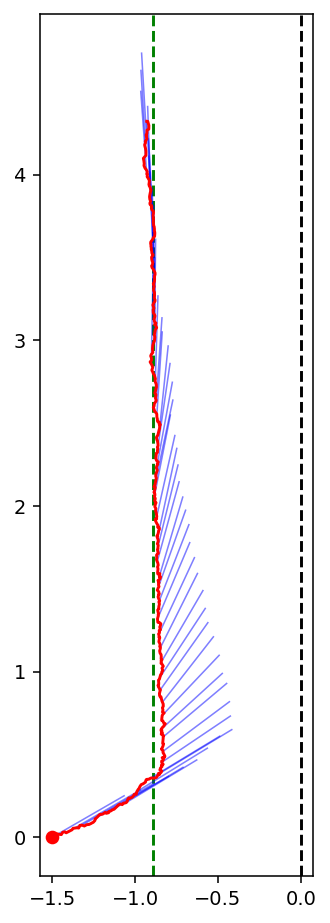

In [3]:
def generate_harmonic(alpha, k):
    @njit
    def tau_func(phi):
        tau = alpha * np.sin(-phi / k)
        return tau
    
    @njit
    def tau_func_deriv(phi):
        tau = -alpha * np.cos(-phi / k) / k
        return tau
    
    return tau_func, tau_func_deriv

N = 500
x0 = -1.5
y0 = 0
phi0 = 30 * np.pi / 180
x = np.ones(N) * x0
y = np.ones(N) * y0
phi = np.ones(N) * phi0

dt = 0.01
Pe = 1
eps = 1e-2

Dt = 1e-3
Dr = 1e-3

alpha_gt = 1
k_gt = 1

tau, dtau = generate_harmonic(alpha=alpha_gt, k=k_gt)
run_abp_core(x, y, phi, dt, tau, Pe=Pe, Dt=Dt, Dr=Dr, eps=eps)
plot_trajectory(x, y, phi)



-486.2498263569765


Text(0.5, 1.0, 'k = 1000')

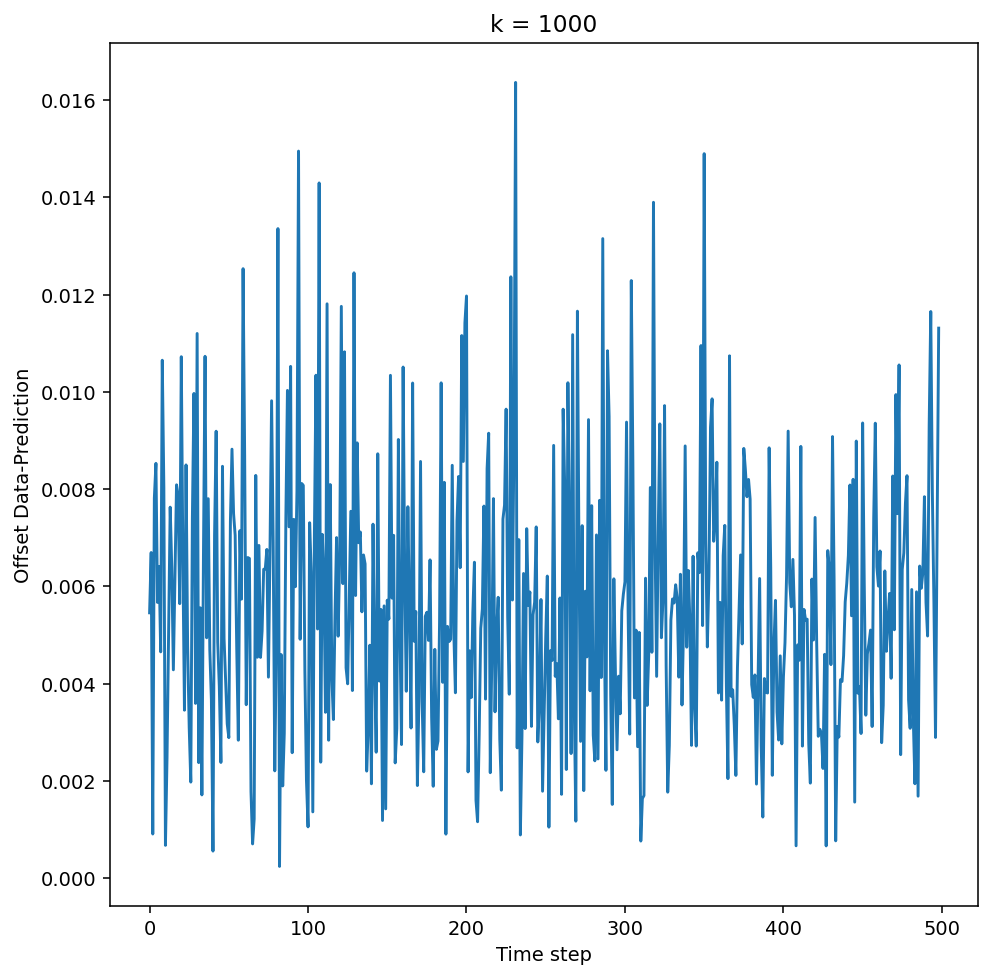

In [4]:
def calc_logl(x, y, dt, tau_func, tau_deriv_func,
            Pe=1, Dt=0, Dr=1, eps=100):
      
    logl = 0
    n_steps = x.shape[0]
    phi_posterior_mean = np.zeros(n_steps-1)
    phi_posterior_std = np.zeros(n_steps-1)
    distance_from_projection = np.zeros(n_steps-1)


    phi_mean = phi0
    phi_std = 5 * np.pi / 180

    for i in range(0, n_steps-1):

        phi_posterior_mean[i] = phi_mean
        phi_posterior_std[i] = phi_std

        F = 0.
        if x[i] > -2**(-1/6):
            F = 24*eps*((1/(x[i]+_EPS_))**13 - 2*(1/(x[i]+_EPS_))**7)

        x_projection = np.cos(phi_mean) * dt * Pe
        y_projection = np.sin(phi_mean) * dt * Pe
        projection_normalization = np.sqrt(x_projection**2 + y_projection**2)

        x_projected = x[i] + x_projection
        y_projected = y[i] + y_projection

        dx = x_projected - (x[i+1] - F * dt)
        dy = y_projected - y[i+1]

        d = np.sqrt(dx**2 + dy**2)
        distance_std = np.sqrt(np.sqrt(2 * Dt * dt)**2 + (phi_std * Pe * dt)**2)

        logl += -0.5 * (d**2) / distance_std**2

        offset = (-dy * x_projection / projection_normalization) + (dx * y_projection / projection_normalization)
        phi_offset_mean = offset / (Pe * dt)
        phi_offset_std = np.sqrt(2 * Dt * dt) / (Pe * dt)

        phi_mean = (phi_std**2 * (phi_mean + phi_offset_mean) + phi_offset_std**2 * phi_mean) / (phi_std**2 + phi_offset_std**2)
        phi_std = np.sqrt(1 / (1/phi_std**2 + 1/phi_offset_std**2) + 2 * Dr * dt)

        distance_from_projection[i] = d

        torque = tau_func(phi_mean) * F - 0.0
        d_torque = tau_deriv_func(phi_mean) * F
        phi_mean += torque * dt
        phi_std *= np.exp(-d_torque * dt)

    return dict(logl=logl,
                distance_from_projection=distance_from_projection,
                phi_posterior_mean=phi_posterior_mean,
                phi_posterior_std=phi_posterior_std)

tau, dtau = generate_harmonic(alpha=alpha_gt, k=k_gt)
res = calc_logl(x, y, dt=dt, tau_func=tau, tau_deriv_func=dtau, Pe=Pe, Dt=Dt, Dr=Dr, eps=1e-2)
plt.plot(res['distance_from_projection'])
print(res['logl'])
plt.xlabel('Time step')
plt.ylabel('Offset Data-Prediction')
plt.title("k = 1000")

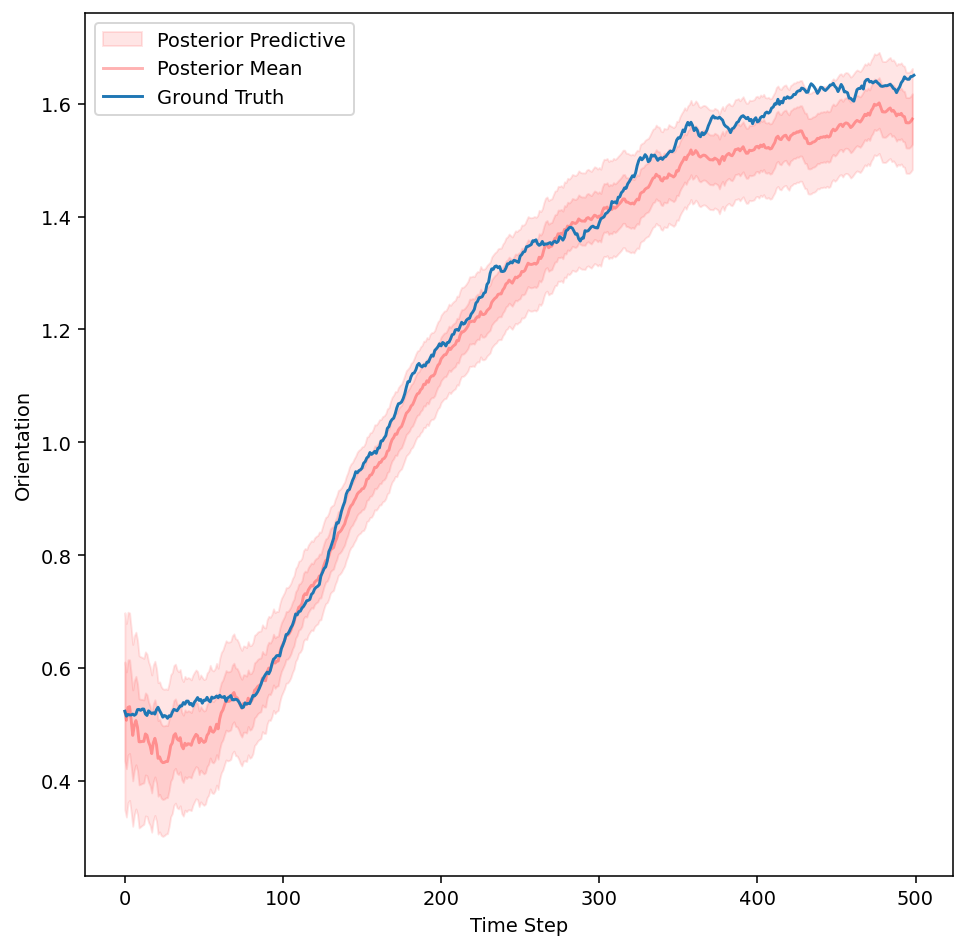

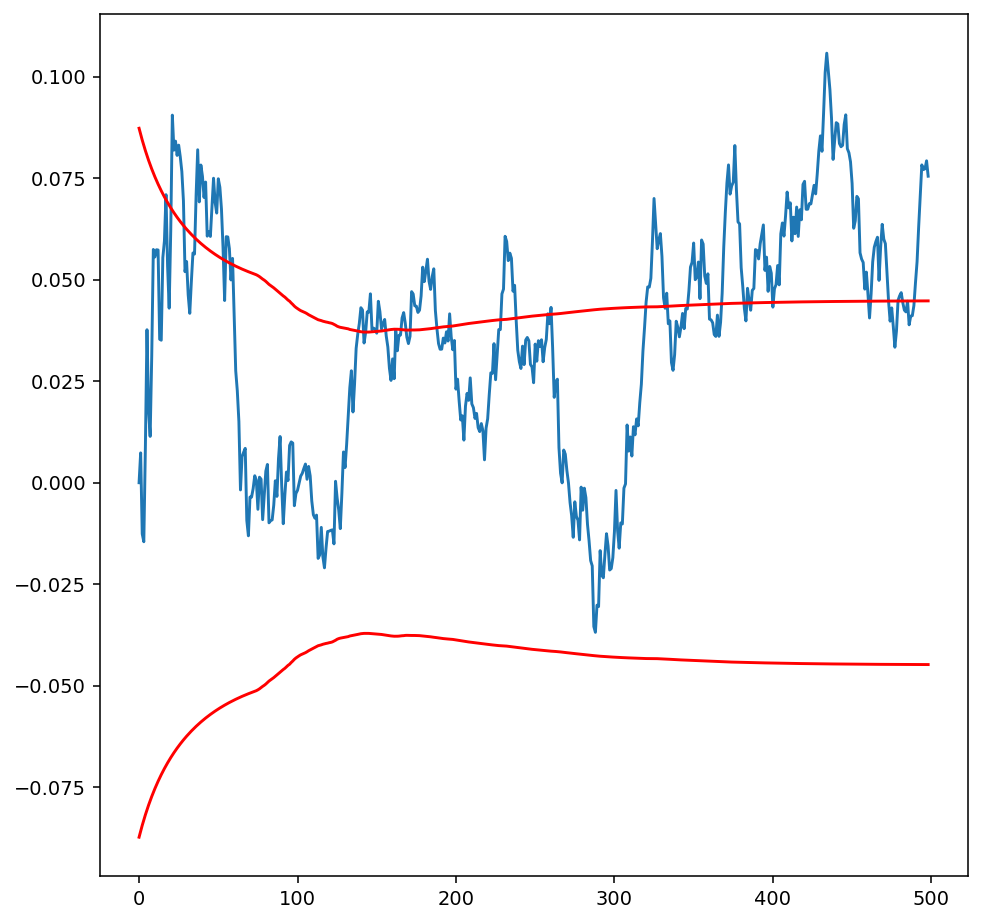

In [5]:
phi_post = res['phi_posterior_mean']
phi_post_std = res['phi_posterior_std']
plt.fill_between(range(phi_post.shape[0]), phi_post - 2*phi_post_std, phi_post + 2*phi_post_std, color='r', alpha=0.1)
plt.fill_between(range(phi_post.shape[0]), phi_post - phi_post_std, phi_post + phi_post_std, color='r', alpha=0.1, label='Posterior Predictive')
plt.plot(phi_post, 'r', label='Posterior Mean', alpha=0.3)

plt.plot(phi, label='Ground Truth')
plt.xlabel('Time Step')
plt.ylabel('Orientation')
plt.legend()

plt.show()

# plot the difference between the ground truth and the posterior mean
plt.plot(phi[:-1] - phi_post)
plt.plot(phi_post_std, color='r')
plt.plot(-phi_post_std, color='r') 



100%|██████████| 80/80 [00:03<00:00, 21.19it/s]


Text(0, 0.5, 'Poster density')

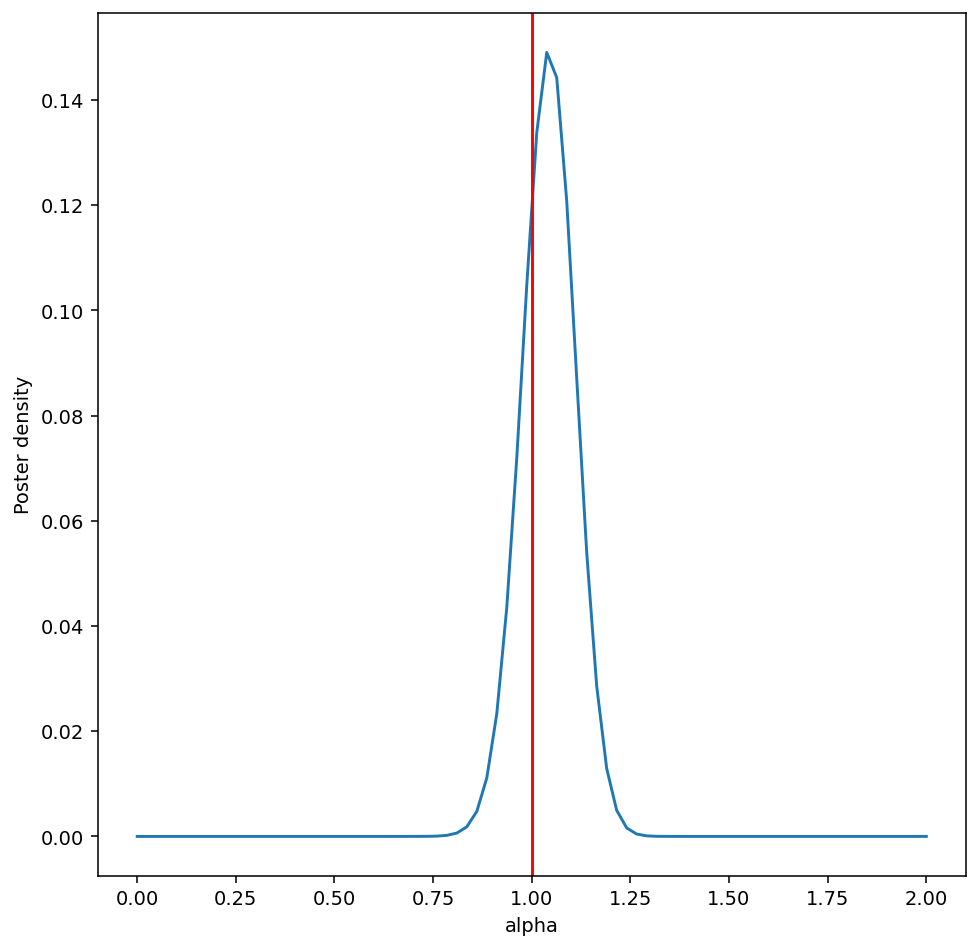

In [6]:
alpha = np.linspace(0, 2 * alpha_gt, 80)
logls = []

for alpha_ in tqdm(alpha):
    tau, dtau = generate_harmonic(alpha=alpha_, k=k_gt)
    res = calc_logl(x, y, dt=dt, tau_func=tau, tau_deriv_func=dtau, Pe=Pe, Dt=Dt, Dr=Dr, eps=1e-2)
    logls.append(res['logl'])

logls = np.array(logls)
logls -= np.max(logls)
p = np.exp(logls)
p /= np.sum(p)
plt.plot(alpha, p)
plt.axvline(alpha_gt, color='r')
plt.xlabel('alpha')
plt.ylabel('Poster density')


In [7]:
resolution =  10
alpha_max = 2 * alpha_gt
alpha = np.linspace(0, alpha_max, resolution)
k_max = 2 * k_gt
k_min = 0.5 * k_gt
k = np.linspace(k_min, k_max, resolution)
logls = []

for alpha_ in tqdm(alpha):
    for k_ in k:
        tau, dtau = generate_harmonic(alpha=alpha_, k=k_)
        res = calc_logl(x, y, dt=dt, tau_func=tau, tau_deriv_func=dtau, Pe=Pe, Dt=Dt, Dr=Dr, eps=1e-2)
        logls.append(res['logl'])

logls = np.array(logls)
logls -= np.max(logls)
p = np.exp(logls)
p /= np.sum(p)
p = p.reshape((resolution, resolution)).T

 30%|███       | 3/10 [00:01<00:03,  2.30it/s]


KeyboardInterrupt: 

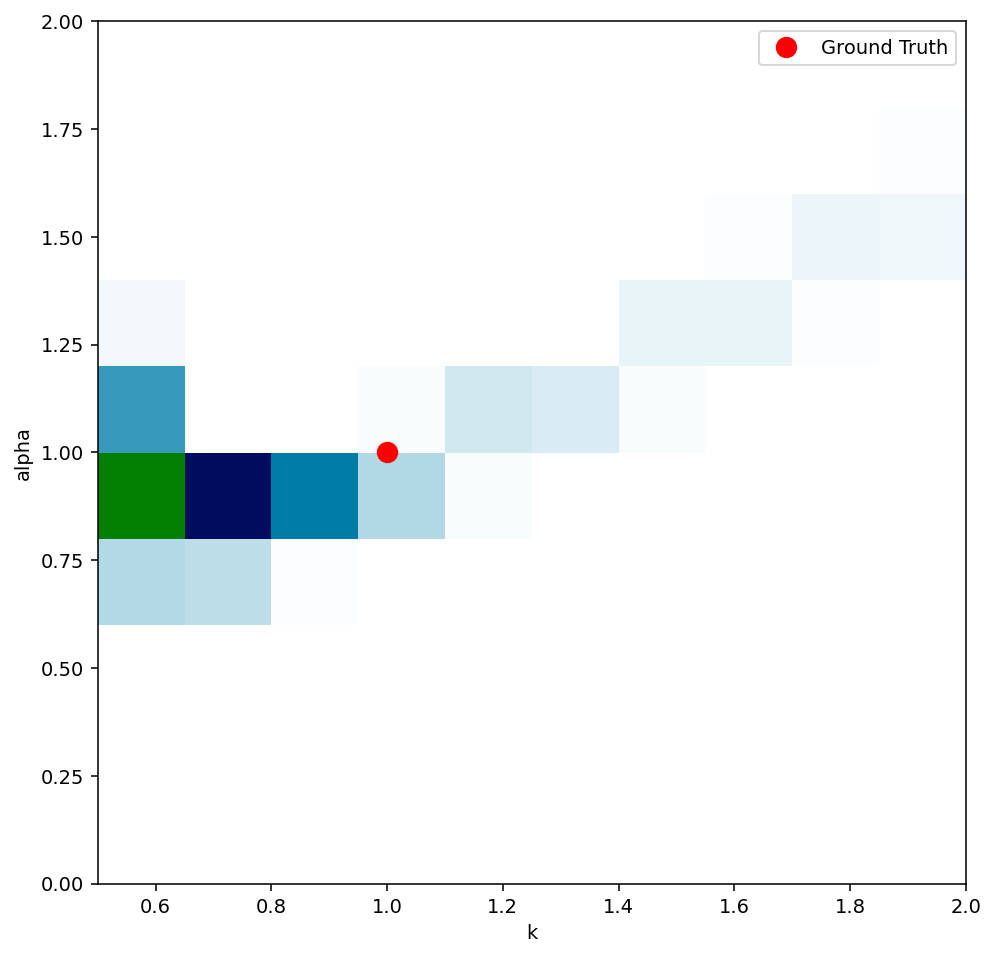

In [ ]:
plt.imshow(p.T, extent=(k_min, k_max, 0, alpha_max), origin='lower', aspect='auto', cmap='ocean_r')
plt.xlabel('k')
plt.ylabel('alpha')
plt.plot(alpha_gt, k_gt, 'ro', markersize=10, label='Ground Truth')

i, j = np.unravel_index(np.argmax(p), p.shape)
#plt.plot(alpha[j], k[i], 'b+', markersize=10, markeredgewidth=2, label='Maximum Likelihood')
plt.legend()